# CRIC field test: can the detector find cells on a whole slide, with no boxes given?

**ELI5.** So far the detector has only seen small pictures with one cell in the middle. Here we hand it a whole CRIC slide with about 30 cells on it and no hints. It has to find the cells itself. We already know where the real cells are, because CRIC experts marked a dot on each nucleus and wrote its severity. So we can mark the detector's homework.

This is the fairest first test: same lab, same stain, same microscope as training, so any failure comes from the sliding-window approach and not from a new dataset. Only slides from the **test split** are used. The detector never saw those slides, because the split was made by slide with seed 42, the same way as in the training notebooks.

**How a slide is processed**
1. Cut the big photo into overlapping 224x224 windows (the size the detector trained on, so nothing gets shrunk).
2. The detector looks at each window and draws boxes with a grade and a confidence.
3. Boxes found twice in overlapping windows are merged.
4. Each expert dot is checked: is it inside a detected box? If yes, that cell was **found**. If the box's grade also matches the expert's, it was **graded right**.

**Before running:** turn the GPU on first, then attach `cervigrade-cric-dataset` and the Kaggle Dataset holding your `.pt` weight files.

In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 5.1 MB/s eta 0:00:00


## 1. Helpers (no model needed)

In [2]:
import random

def short(name):
    return "Negative" if name.startswith("Negative") else name

def tile_starts(length, tile, stride):
    last = max(length - tile, 0)
    starts = list(range(0, last + 1, stride))
    if starts[-1] != last:
        starts.append(last)
    return starts

def figshare_id_from_doi(doi):
    return doi.rstrip("/").split("figshare.")[-1]

def split_by_group_global(groups_all, seed=42, train_frac=0.7, val_frac=0.15):
    # Same logic and seed as the training notebooks, so the test slides are the same ones.
    rng = random.Random(seed)
    groups = sorted(set(groups_all))
    rng.shuffle(groups)
    n = len(groups)
    n_train, n_val = round(n * train_frac), round(n * val_frac)
    out = {}
    for g in groups[:n_train]: out[g] = "train"
    for g in groups[n_train:n_train + n_val]: out[g] = "val"
    for g in groups[n_train + n_val:]: out[g] = "test"
    return out

def point_in_box(px, py, box):
    x1, y1, x2, y2 = box
    return x1 <= px <= x2 and y1 <= py <= y2

## 2. Find the CRIC slides, the expert labels and the weights

The notebook searches `/kaggle/input` for `classifications.csv` (the expert labels) and the `images` folder next to it (the full slides). Only 6-class weights are kept; the Stage 1 cell-finder can't grade.

In [3]:
import os, glob
import pandas as pd
from ultralytics import YOLO

INPUT_ROOT = "/kaggle/input"

csv_path = None
for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
    if "classifications.csv" in filenames:
        csv_path = os.path.join(dirpath, "classifications.csv")
        break
assert csv_path, "classifications.csv not found: open the dataset's file browser and check CRIC_dataset/ was published with it."
CRIC_ROOT = os.path.dirname(csv_path)
CRIC_IMAGES_DIR = os.path.join(CRIC_ROOT, "images")
assert os.path.isdir(CRIC_IMAGES_DIR), f"No images folder at {CRIC_IMAGES_DIR}: the full slides were not published in this dataset."
print("CRIC root:", CRIC_ROOT, "| slide files:", len(os.listdir(CRIC_IMAGES_DIR)))

cric = pd.read_csv(csv_path)
cric["fsid"] = cric["image_doi"].apply(figshare_id_from_doi)
cric["on_disk"] = cric["fsid"] + "_" + cric["image_filename"]
cric["group"] = cric["image_id"].astype(str)

split_map = split_by_group_global(cric["group"])
cric["split"] = cric["group"].map(split_map)
test = cric[cric["split"] == "test"].copy()
print(f"\nSlides: {cric['group'].nunique()} total, {test['group'].nunique()} in the test split")
print(f"Expert-marked cells on test slides: {len(test)}  (the classifier notebooks' CRIC test split has 1723, so this should match)")
print(test["bethesda_system"].value_counts())

models = {}
for p in sorted(glob.glob(f"{INPUT_ROOT}/**/*.pt", recursive=True)):
    m = YOLO(p)
    if len(m.names) == 6:
        models[p] = m
        print("\nSEVERITY MODEL:", p, "|", [short(n) for n in m.names.values()])
assert models, "No 6-class weights found. Attach the weights dataset."

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CRIC root: /kaggle/input/datasets/wagnermushayija/cervigrade-cric-dataset/CRIC_dataset | slide files: 400

Slides: 400 total, 60 in the test split
Expert-marked cells on test slides: 1723  (the classifier notebooks' CRIC test split has 1723, so this should match)
bethesda_system
Negative for intraepithelial lesion    985
HSIL                                   418
LSIL                                   129
ASC-US                                 108
ASC-H                                   49
SCC                                     34
Name: count, dtype: int64

SEVERITY MODEL: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt | ['ASC-H', 'ASC-US', 'HSIL', 'LSIL', 'Ne

## 3. The detector: slide a window, merge duplicates

The detector keeps everything above confidence 0.25. Stricter confidence cutoffs are tried afterwards without re-running it.

In [4]:
import cv2, time
import numpy as np
import torch
from torchvision.ops import nms
import matplotlib.pyplot as plt

TILE, STRIDE, LOW_CONF = 224, 112, 0.25

def detect_field(model, img_bgr, conf=LOW_CONF):
    H, W = img_bgr.shape[:2]
    tiles, offsets = [], []
    for y in tile_starts(H, TILE, STRIDE):
        for x in tile_starts(W, TILE, STRIDE):
            tiles.append(img_bgr[y:y + TILE, x:x + TILE])
            offsets.append((x, y))
    results = model.predict(tiles, imgsz=224, conf=conf, verbose=False, batch=64)
    boxes, scores, classes = [], [], []
    for r, (ox, oy) in zip(results, offsets):
        if r.boxes is None or len(r.boxes) == 0:
            continue
        xyxy = r.boxes.xyxy.cpu().numpy().copy()
        xyxy[:, [0, 2]] += ox
        xyxy[:, [1, 3]] += oy
        boxes.append(xyxy)
        scores.append(r.boxes.conf.cpu().numpy())
        classes.append(r.boxes.cls.cpu().numpy().astype(int))
    if not boxes:
        return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=int)
    boxes = np.concatenate(boxes); scores = np.concatenate(scores); classes = np.concatenate(classes)
    keep = nms(torch.tensor(boxes), torch.tensor(scores), 0.5).numpy()
    return boxes[keep], scores[keep], classes[keep]

def load_slide(on_disk):
    return cv2.imread(os.path.join(CRIC_IMAGES_DIR, on_disk))

## 4. Look first: two slides with the expert dots and the detector's boxes

Yellow dots are the experts' marks. Green boxes are what the detector found at confidence 0.5 or higher. If green boxes sit around yellow dots, the approach works. Green boxes in empty space are false alarms. Note that CRIC's experts did not necessarily mark every cell, so a box with no dot is not always wrong.

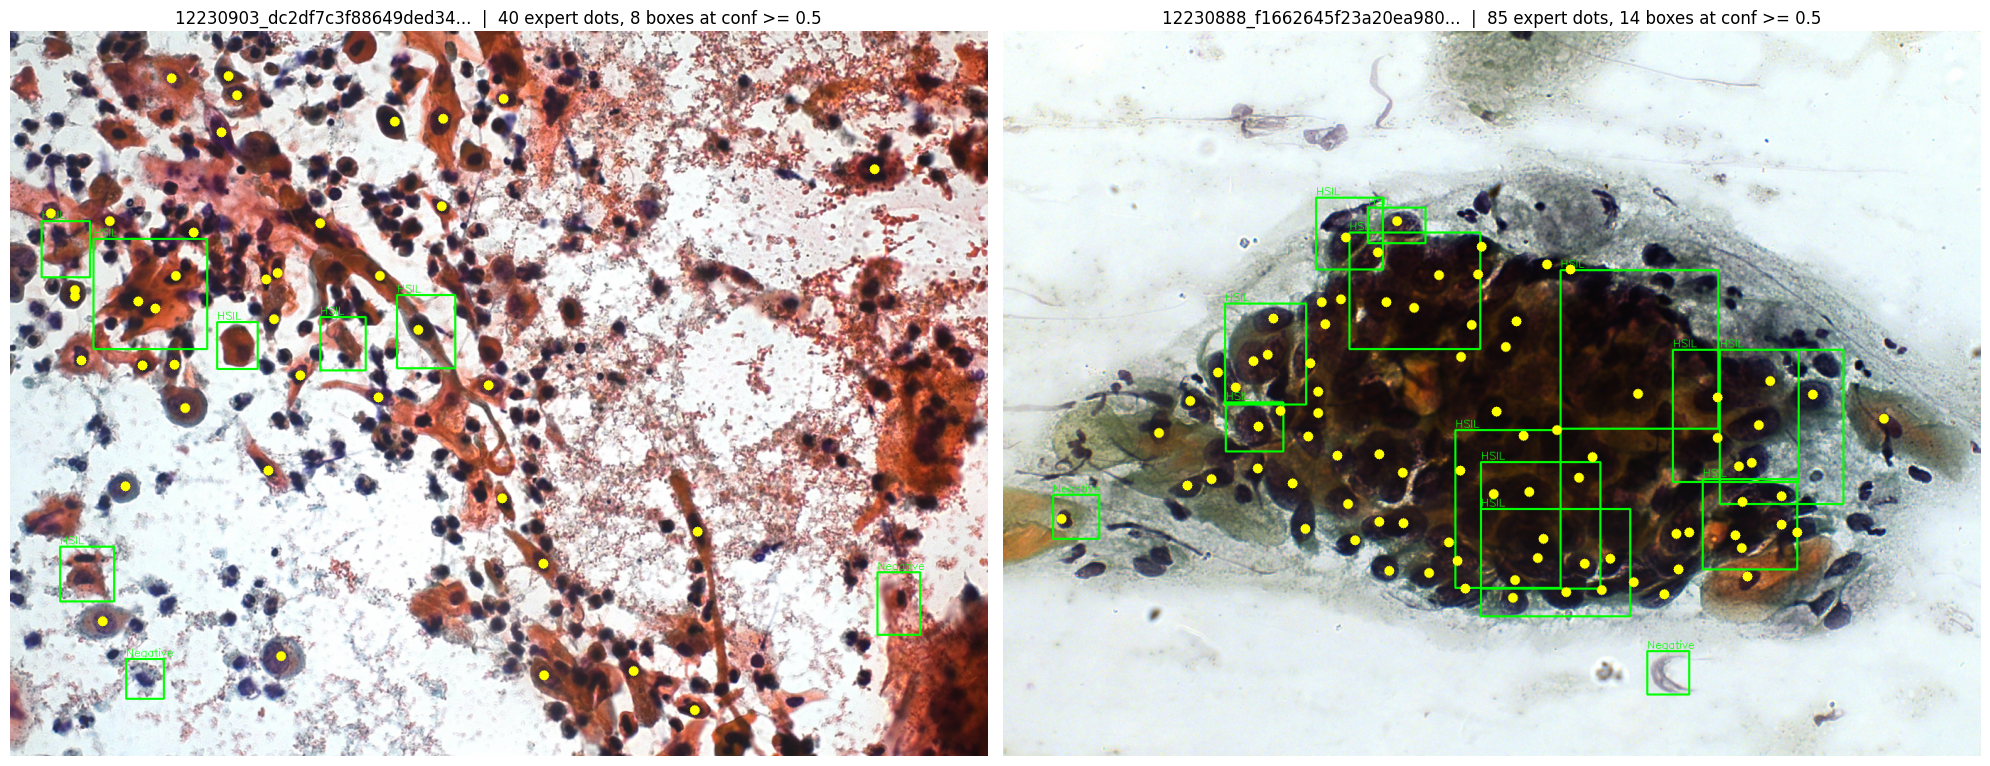

In [5]:
SHOW_THR = 0.5
first_path, first_model = next(iter(models.items()))
show_slides = test["on_disk"].drop_duplicates().iloc[:2].tolist()

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, on_disk in zip(axes, show_slides):
    img = load_slide(on_disk)
    boxes, scores, classes = detect_field(first_model, img)
    vis = img.copy()
    for (x1, y1, x2, y2), s, c in zip(boxes, scores, classes):
        if s < SHOW_THR:
            continue
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(vis, short(first_model.names[c]), (int(x1), max(int(y1) - 4, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    for _, r in test[test["on_disk"] == on_disk].iterrows():
        cv2.circle(vis, (int(r["nucleus_x"]), int(r["nucleus_y"])), 7, (0, 255, 255), -1)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    n_marked = (test["on_disk"] == on_disk).sum()
    ax.set_title(f"{on_disk[:28]}...  |  {n_marked} expert dots, {(scores >= SHOW_THR).sum()} boxes at conf >= {SHOW_THR}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("cric_field_picture_check.png", dpi=100)
plt.show()

## 5. Run on the test slides and score it

Each expert dot is either **found** (inside any detected box at that confidence) or **missed**. Among the found ones, **graded right** means the box's grade equals the expert's. The last column counts boxes with no expert dot inside, per slide. That is an upper bound on false alarms, since not every real cell was marked.

`MAX_SLIDES = 15` keeps the first run short. Set it to `None` to use every test slide.

In [6]:
MAX_SLIDES = 15
slides = test["on_disk"].drop_duplicates().tolist()
if MAX_SLIDES:
    slides = slides[:MAX_SLIDES]
print(f"Scoring {len(slides)} test slides")

dets = {}   # (weights, slide) -> (boxes, scores, classes)
for wpath, model in models.items():
    t0 = time.time()
    for s in slides:
        dets[(wpath, s)] = detect_field(model, load_slide(s))
    print(f"{os.path.basename(wpath)}: {time.time() - t0:.0f}s for {len(slides)} slides")

THRESHOLDS = [0.25, 0.4, 0.5, 0.6, 0.7]
for wpath, model in models.items():
    print("=" * 78)
    print("WEIGHTS:", wpath)
    rows = []
    per_class = {}
    for thr in THRESHOLDS:
        found = graded = total = extra = n_boxes = 0
        for s in slides:
            boxes, scores, classes = dets[(wpath, s)]
            keep = scores >= thr
            boxes, classes = boxes[keep], classes[keep]
            n_boxes += len(boxes)
            sub = test[test["on_disk"] == s]
            used = np.zeros(len(boxes), dtype=bool)
            for _, r in sub.iterrows():
                total += 1
                px, py = r["nucleus_x"], r["nucleus_y"]
                hits = [i for i, b in enumerate(boxes) if point_in_box(px, py, b)]
                if hits:
                    found += 1
                    used[hits] = True
                    # best hit = the smallest box around the dot
                    best = min(hits, key=lambda i: (boxes[i][2] - boxes[i][0]) * (boxes[i][3] - boxes[i][1]))
                    ok = short(model.names[classes[best]]) == short(r["bethesda_system"])
                    graded += ok
                    if thr == 0.5:
                        c = short(r["bethesda_system"])
                        a = per_class.setdefault(c, [0, 0, 0])
                        a[0] += 1; a[1] += 1; a[2] += ok
                elif thr == 0.5:
                    c = short(r["bethesda_system"])
                    a = per_class.setdefault(c, [0, 0, 0])
                    a[0] += 1
            extra += int((~used).sum())
        rows.append({"conf >=": thr,
                     "cells found": f"{found}/{total} ({found / total:.0%})",
                     "found AND graded right": f"{graded}/{found if found else 1} ({graded / max(found, 1):.0%})",
                     "boxes with no expert dot": f"{extra} of {n_boxes}"})
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nPer expert class at conf >= 0.5:")
    for c, (tot, f, g) in sorted(per_class.items()):
        print(f"  {c:9s}: found {f}/{tot} ({f / tot:.0%}), graded right {g}/{max(f, 1)} ({g / max(f, 1):.0%})")

Scoring 15 test slides
stage2_severity_best.pt: 3s for 15 slides
stage2_severity_oversampled_best.pt: 3s for 15 slides
WEIGHTS: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt
 conf >=   cells found found AND graded right boxes with no expert dot
    0.25 307/507 (61%)          254/307 (83%)               484 of 745
    0.40 184/507 (36%)          159/184 (86%)               203 of 335
    0.50 103/507 (20%)           87/103 (84%)               109 of 173
    0.60  59/507 (12%)            53/59 (90%)                 37 of 65
    0.70   25/507 (5%)            21/25 (84%)                  3 of 11

Per expert class at conf >= 0.5:
  ASC-US   : found 5/13 (38%), graded right 0/5 (0%)
  HSIL     : found 42/88 (48%), graded right 42/42 (100%)
  LSIL     : found 10/65 (15%), graded right 0/10 (0%)
  Negative : found 45/323 (14%), graded right 45/45 (100%)
  SCC      : found 1/18 (6%), graded right 0/1 (0%)
WEIGHTS: /kaggle/input/datasets/wagnermushayija/ce

## How to read this

- **Cells found** answers the question you asked: without being told where the cells are, does the detector find them? Compare the picture check with the percentages.
- **Found AND graded right** is the severity half. Expect it to look like the Stage 2 results: good on Negative and HSIL, weak on the rare classes.
- **Boxes with no expert dot** is the false-alarm check. The detector only ever trained on tight crops with a cell in the middle, so it has barely seen empty background. If this number is huge, that is why, and raising the confidence cutoff or adding background examples to training are the fixes.
- Only after this looks reasonable is the Mendeley test (`mendeley_pipeline_test.ipynb`) worth reading closely.

## 6. Stricter scoring on all 60 test slides

The first run used 15 slides and a loose rule: a cell counted as "found" if its dot sat inside any box. A single clump-sized box could therefore "find" ten cells at once. This section fixes both problems.

- **All 60 test slides** are used, so every class has its full count (34 SCC cells instead of 18).
- **Strict matching:** a dot and a box pair up only if the dot is inside the box and the box is cell-sized (longest side at most `MAX_BOX_SIDE` pixels). Each box and each dot can be used once, closest centre first.
- **Clump boxes** (longer than `MAX_BOX_SIDE`) are counted separately. They show how often the detector boxes a blob instead of a cell.
- **Found AND right, of all cells** is the most honest per-class number. It cannot look good by finding only the easy cells.

In [7]:
# Compare the boxes the detector was TRAINED on with the boxes it draws on whole slides.
cb_path = None
for dp, dn, fn in os.walk("/kaggle/input"):
    if "cric_boxes.csv" in fn:
        cb_path = os.path.join(dp, "cric_boxes.csv")
        break
assert cb_path, "cric_boxes.csv not found: attach the cervigrade-cell-boxes dataset."

cb = pd.read_csv(cb_path)
cb = cb[cb["ok"] == True]
side = np.maximum(cb["x_max"] - cb["x_min"], cb["y_max"] - cb["y_min"])
print(f"Training boxes (CRIC, {len(cb)} crops), longest side in px:")
print(side.describe(percentiles=[.1, .5, .9, .99]).round(0).to_string())

Training boxes (CRIC, 8944 crops), longest side in px:
count    8944.0
mean       99.0
std        39.0
min        45.0
10%        56.0
50%        91.0
90%       157.0
99%       200.0
max       200.0


In [8]:
if "dets" not in globals():
    dets = {}
ALL_SLIDES = test["on_disk"].drop_duplicates().tolist()
print(f"{len(ALL_SLIDES)} test slides")

for wpath, model in models.items():
    t0 = time.time()
    n_new = 0
    for s in ALL_SLIDES:
        if (wpath, s) not in dets:          # reuses slides already computed
            dets[(wpath, s)] = detect_field(model, load_slide(s))
            n_new += 1
    print(f"{os.path.basename(wpath)}: {n_new} new slides in {time.time() - t0:.0f}s")

60 test slides
stage2_severity_best.pt: 45 new slides in 10s
stage2_severity_oversampled_best.pt: 45 new slides in 8s


In [9]:
MAX_BOX_SIDE = 150          # a box with a side longer than this counts as a "clump box", not one cell
THRS = [0.25, 0.4, 0.5]
CLASS_THRS = [0.25, 0.4]
CLASS_ORDER = ["Negative", "ASC-US", "LSIL", "ASC-H", "HSIL", "SCC"]

def match_slide(boxes, scores, classes, dots, thr, max_side):
    # One-to-one: a dot and a box pair up only if the dot is inside the box and the box is cell-sized.
    # Closest centre wins, and each box and each dot can be used once.
    keep = scores >= thr
    b, c = boxes[keep], classes[keep]
    cand = []
    for di, (px, py) in enumerate(dots):
        for bi in range(len(b)):
            x1, y1, x2, y2 = b[bi]
            if max(x2 - x1, y2 - y1) > max_side:
                continue
            if x1 <= px <= x2 and y1 <= py <= y2:
                cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                cand.append(((px - cx) ** 2 + (py - cy) ** 2, di, bi))
    cand.sort()
    used_d, used_b, pairs = set(), set(), {}
    for _, di, bi in cand:
        if di in used_d or bi in used_b:
            continue
        used_d.add(di); used_b.add(bi); pairs[di] = bi
    return pairs, b, c

for wpath, model in models.items():
    print("=" * 84)
    print("WEIGHTS:", wpath)

    sides = []
    for s in ALL_SLIDES:
        bx, sc, cl = dets[(wpath, s)]
        sides += list(np.maximum(bx[sc >= 0.25][:, 2] - bx[sc >= 0.25][:, 0],
                                 bx[sc >= 0.25][:, 3] - bx[sc >= 0.25][:, 1]))
    if sides:
        print("Detected box size at conf >= 0.25 (longest side, px): "
              f"median {np.median(sides):.0f}, 75th pct {np.percentile(sides, 75):.0f}, "
              f"90th pct {np.percentile(sides, 90):.0f}, share over {MAX_BOX_SIDE}px: "
              f"{np.mean(np.array(sides) > MAX_BOX_SIDE):.0%}")

    rows, per_class = [], {}
    for thr in THRS:
        tot = found = right = loose = kept = clump = 0
        for s in ALL_SLIDES:
            bx, sc, cl = dets[(wpath, s)]
            sub = test[test["on_disk"] == s]
            dots = list(zip(sub["nucleus_x"], sub["nucleus_y"]))
            labels = [short(x) for x in sub["bethesda_system"]]
            pairs, b, c = match_slide(bx, sc, cl, dots, thr, MAX_BOX_SIDE)
            kept += len(b)
            clump += int(((np.maximum(b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]) if len(b) else np.zeros(0)) > MAX_BOX_SIDE).sum())
            for di, (px, py) in enumerate(dots):
                tot += 1
                loose += any(x1 <= px <= x2 and y1 <= py <= y2 for x1, y1, x2, y2 in b)
                is_found = di in pairs
                is_right = is_found and short(model.names[c[pairs[di]]]) == labels[di]
                found += is_found
                right += is_right
                if thr in CLASS_THRS:
                    a = per_class.setdefault((thr, labels[di]), [0, 0, 0])
                    a[0] += 1; a[1] += is_found; a[2] += is_right
        rows.append({"conf >=": thr,
                     "boxes kept": kept,
                     "clump boxes": f"{clump / max(kept, 1):.0%}",
                     "found (strict)": f"{found / tot:.0%}",
                     "graded right, of found": f"{right / max(found, 1):.0%}",
                     "found AND right, of all cells": f"{right / tot:.0%}",
                     "old loose 'found'": f"{loose / tot:.0%}"})
    print(pd.DataFrame(rows).to_string(index=False))

    for thr in CLASS_THRS:
        print(f"\nPer expert class at conf >= {thr}  (found / found-and-graded-right / total):")
        for cls in CLASS_ORDER:
            t, f, r = per_class.get((thr, cls), [0, 0, 0])
            if t:
                print(f"  {cls:9s}: {f:4d} / {r:4d} / {t:4d}   "
                      f"(found {f / t:.0%}, found-and-right {r / t:.0%})")

WEIGHTS: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt
Detected box size at conf >= 0.25 (longest side, px): median 81, 75th pct 119, 90th pct 162, share over 150px: 14%
 conf >=  boxes kept clump boxes found (strict) graded right, of found found AND right, of all cells old loose 'found'
    0.25        2787         14%            39%                    77%                           30%               62%
    0.40        1231         18%            18%                    79%                           15%               36%
    0.50         626         22%             8%                    81%                            7%               20%

Per expert class at conf >= 0.25  (found / found-and-graded-right / total):
  Negative :  402 /  391 /  985   (found 41%, found-and-right 40%)
  ASC-US   :   50 /    0 /  108   (found 46%, found-and-right 0%)
  LSIL     :   51 /   12 /  129   (found 40%, found-and-right 9%)
  ASC-H    :   19 /    1 /   49   (foun

In [10]:
RANK = {"Negative": 0, "ASC-US": 1, "LSIL": 2, "ASC-H": 3, "HSIL": 4, "SCC": 5}
INV = {v: k for k, v in RANK.items()}

all_slides = test["on_disk"].drop_duplicates().tolist()

expert = {}
for s in all_slides:
    sub = test[test["on_disk"] == s]
    expert[s] = INV[max(RANK[short(c)] for c in sub["bethesda_system"])]

VERDICT_THRS = [0.25, 0.4, 0.5, 0.6]

for wpath, model in models.items():
    for s in all_slides:
        if (wpath, s) not in dets:
            dets[(wpath, s)] = detect_field(model, load_slide(s))

    print("=" * 78)
    print("WEIGHTS:", wpath)
    rows = []
    for thr in VERDICT_THRS:
        exact = refer_tp = refer_pos = hi_tp = hi_pos = n = 0
        pred_by_slide = {}
        for s in all_slides:
            boxes, scores, classes = dets[(wpath, s)]
            keep = scores >= thr
            ranks = [RANK[short(model.names[c])] for c in classes[keep]]
            pred = INV[max(ranks)] if ranks else "Negative"
            pred_by_slide[s] = pred
            e = expert[s]
            n += 1
            exact += pred == e
            if RANK[e] > 0:
                refer_pos += 1; refer_tp += RANK[pred] > 0
            if RANK[e] >= 3:
                hi_pos += 1; hi_tp += RANK[pred] >= 3
        rows.append({"conf >=": thr,
                     "exact match": f"{exact}/{n} ({exact / n:.0%})",
                     "abnormal slides flagged": f"{refer_tp}/{refer_pos}",
                     "high-grade slides flagged": f"{hi_tp}/{hi_pos}"})
        if thr == 0.5:
            conf_tab = pd.crosstab(pd.Series({s: expert[s] for s in all_slides}, name="expert worst"),
                                   pd.Series(pred_by_slide, name="detector worst"))
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nExpert worst grade vs detector worst grade (conf >= 0.5):")
    print(conf_tab)

WEIGHTS: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt
 conf >= exact match abnormal slides flagged high-grade slides flagged
    0.25 24/60 (40%)                   41/49                     15/15
    0.40 23/60 (38%)                   26/49                     13/15
    0.50 19/60 (32%)                   12/49                     10/15
    0.60 17/60 (28%)                   10/49                      8/15

Expert worst grade vs detector worst grade (conf >= 0.5):
detector worst  HSIL  LSIL  Negative  SCC
expert worst                             
ASC-H              0     0         3    0
ASC-US             0     0        16    0
HSIL               5     0         1    0
LSIL               0     2        16    0
Negative           0     0        11    0
SCC                4     0         1    1
WEIGHTS: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_oversampled_best.pt
 conf >= exact match abnormal slides flagged high-

In [11]:
def group(rank):
    return "healthy" if rank == 0 else ("mild" if rank <= 2 else "serious")

real_groups = {s: group(RANK[expert[s]]) for s in all_slides}

for wpath, model in models.items():
    print("=" * 70)
    print("MODEL:", os.path.basename(wpath))
    for thr in [0.25, 0.5]:
        print(f"\n--- confidence cutoff {thr} ---")
        said = {s: None for s in all_slides}
        for s in all_slides:
            boxes, scores, classes = dets[(wpath, s)]
            keep = scores >= thr
            ranks = [RANK[short(model.names[c])] for c in classes[keep]]
            said[s] = group(max(ranks)) if ranks else "healthy"
        for real in ["healthy", "mild", "serious"]:
            slides_g = [s for s in all_slides if real_groups[s] == real]
            counts = {a: sum(said[s] == a for s in slides_g) for a in ["healthy", "mild", "serious"]}
            print(f"{len(slides_g):2d} {real.upper():8s} slides -> "
                  f"called healthy: {counts['healthy']:2d} | called mild: {counts['mild']:2d} | called serious: {counts['serious']:2d}")

MODEL: stage2_severity_best.pt

--- confidence cutoff 0.25 ---
11 HEALTHY  slides -> called healthy:  8 | called mild:  3 | called serious:  0
34 MILD     slides -> called healthy:  8 | called mild: 18 | called serious:  8
15 SERIOUS  slides -> called healthy:  0 | called mild:  0 | called serious: 15

--- confidence cutoff 0.5 ---
11 HEALTHY  slides -> called healthy: 11 | called mild:  0 | called serious:  0
34 MILD     slides -> called healthy: 32 | called mild:  2 | called serious:  0
15 SERIOUS  slides -> called healthy:  5 | called mild:  0 | called serious: 10
MODEL: stage2_severity_oversampled_best.pt

--- confidence cutoff 0.25 ---
11 HEALTHY  slides -> called healthy:  4 | called mild:  4 | called serious:  3
34 MILD     slides -> called healthy:  2 | called mild:  8 | called serious: 24
15 SERIOUS  slides -> called healthy:  0 | called mild:  0 | called serious: 15

--- confidence cutoff 0.5 ---
11 HEALTHY  slides -> called healthy: 10 | called mild:  0 | called serious:  1
